# TP2: Procesamiento de archivo PDF
`Alumno:` Emiliano Abraham

`Materia:` Procesamiento del Habla

`Link del archivo:` https://dialnet.unirioja.es/descarga/articulo/10572464.pdf

Para el segundo proyecto de la materia, seleccione un ensayo en PDF de la Universidad Veracruzana en la revista Arandu (Mexico) que trata sobre los modelos de inteligencia artificial generativa y LLM.



In [ ]:
#Instalo dependencias que no incluye google colab
!pip install -q pymupdf pdfplumber

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


# 1. Exportar PDF

In [ ]:
#Importo las librerias necesarias para el tp
import requests
import pymupdf
import pdfplumber
import pandas as pd
import re
import string
from collections import Counter
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import matplotlib.pyplot as plt
from IPython.display import Image, display

In [ ]:
URL = "https://dialnet.unirioja.es/descarga/articulo/10572464.pdf"
ARCHIVO = "Analisis_LLM" #Nombre por el que se guarda el archivo

r = requests.get(URL) #Obtengo el archivo
r.raise_for_status #Verifico si se bajo con exito

with open(ARCHIVO, "wb") as f:
  f.write(r.content)

print(f"Status {r.status_code}")
print(f"Tipo: {r.headers.get("Content-Type")}")

Status 200
Tipo: application/pdf


# 2. Extraer Metadatos

In [ ]:
doc = pymupdf.open(ARCHIVO)
meta = doc.metadata

meta

{'format': 'PDF 1.7',
 'title': '',
 'author': '',
 'subject': '',
 'keywords': '',
 'creator': 'Microsoft® Word 2019',
 'producer': 'Microsoft® Word 2019',
 'creationDate': "D:20251007153437-03'00'",
 'modDate': "D:20251007153437-03'00'",
 'trapped': '',
 'encryption': None}

# 3. Texto en crudo


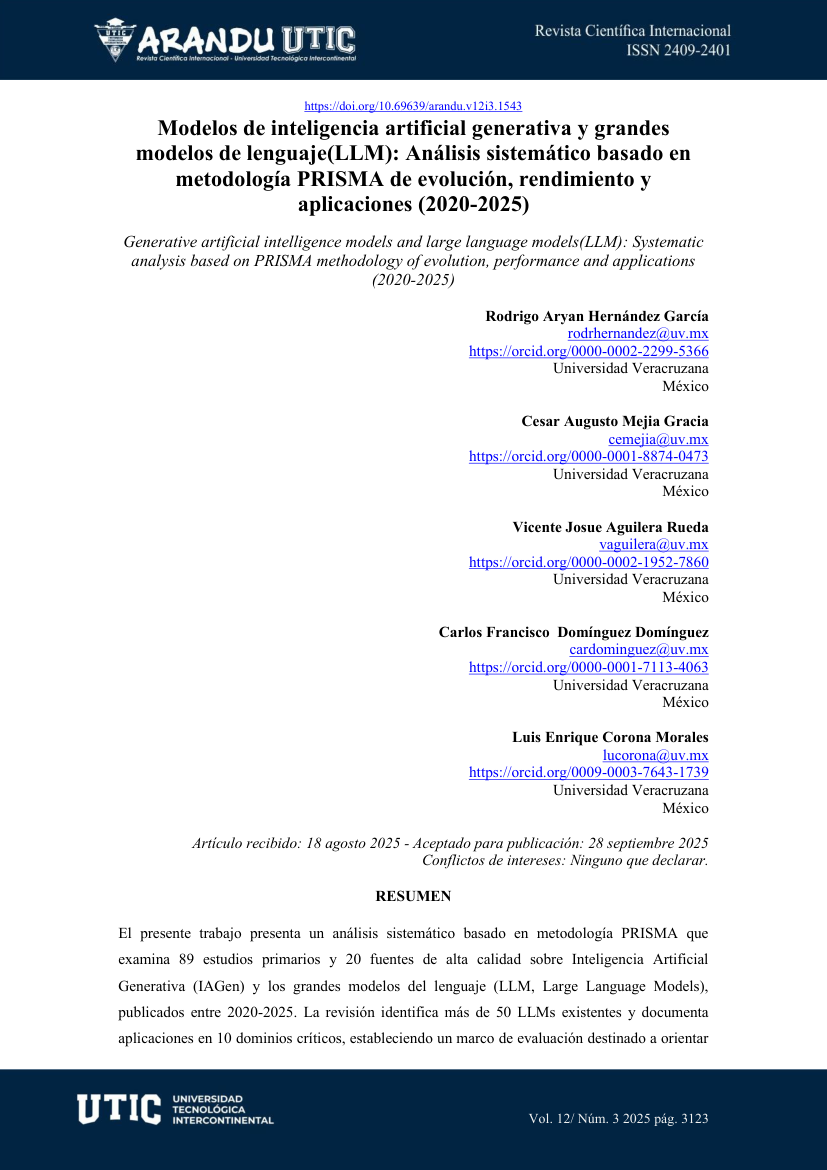

In [ ]:
pagina = doc[0]

imagen = pagina.get_pixmap(dpi=100)
display(Image(imagen.tobytes('png')))

In [ ]:
texto = pagina.get_text()

print(texto)

 
Vol. 12/ Núm. 3 2025 pág. 3123 
https://doi.org/10.69639/arandu.v12i3.1543 
Modelos de inteligencia artificial generativa y grandes 
modelos de lenguaje(LLM): Análisis sistemático basado en 
metodología PRISMA de evolución, rendimiento y 
aplicaciones (2020-2025) 
 
Generative artificial intelligence models and large language models(LLM): Systematic 
analysis based on PRISMA methodology of evolution, performance and applications 
(2020-2025) 
 
Rodrigo Aryan Hernández García 
rodrhernandez@uv.mx 
https://orcid.org/0000-0002-2299-5366 
Universidad Veracruzana 
México 
 
Cesar Augusto Mejia Gracia 
cemejia@uv.mx  
https://orcid.org/0000-0001-8874-0473 
Universidad Veracruzana 
México 
 
Vicente Josue Aguilera Rueda 
vaguilera@uv.mx  
https://orcid.org/0000-0002-1952-7860  
Universidad Veracruzana 
 México 
 
Carlos Francisco  Domínguez Domínguez  
cardominguez@uv.mx  
https://orcid.org/0000-0001-7113-4063 
Universidad Veracruzana 
México 
 
Luis Enrique Corona Morales  
lucorona@uv.mx 

In [ ]:
print(repr(texto))

' \nVol. 12/ Núm. 3 2025 pág. 3123 \nhttps://doi.org/10.69639/arandu.v12i3.1543 \nModelos de inteligencia artificial generativa y grandes \nmodelos de lenguaje(LLM): Análisis sistemático basado en \nmetodología PRISMA de evolución, rendimiento y \naplicaciones (2020-2025) \n \nGenerative artificial intelligence models and large language models(LLM): Systematic \nanalysis based on PRISMA methodology of evolution, performance and applications \n(2020-2025) \n \nRodrigo Aryan Hernández García \nrodrhernandez@uv.mx \nhttps://orcid.org/0000-0002-2299-5366 \nUniversidad Veracruzana \nMéxico \n \nCesar Augusto Mejia Gracia \ncemejia@uv.mx  \nhttps://orcid.org/0000-0001-8874-0473 \nUniversidad Veracruzana \nMéxico \n \nVicente Josue Aguilera Rueda \nvaguilera@uv.mx  \nhttps://orcid.org/0000-0002-1952-7860  \nUniversidad Veracruzana \n México \n \nCarlos Francisco  Domínguez Domínguez  \ncardominguez@uv.mx  \nhttps://orcid.org/0000-0001-7113-4063 \nUniversidad Veracruzana \nMéxico \n \nLuis Enr

# 4. Analisis Estructural del Texto

In [ ]:
texto_pagina = [p.get_text() for p in doc] #Obtengo el texto de cada pagina
texto_completo = "".join(texto_pagina) #Unifico los textos de cada pagina

print(f"El PDF cuenta con un todal de {len(texto_completo)} palabras")
print("---------------------------------------------------------------")
print(repr(texto_completo[:1500]))


El PDF cuenta con un todal de 26545 palabras
---------------------------------------------------------------
' \nVol. 12/ Núm. 3 2025 pág. 3123 \nhttps://doi.org/10.69639/arandu.v12i3.1543 \nModelos de inteligencia artificial generativa y grandes \nmodelos de lenguaje(LLM): Análisis sistemático basado en \nmetodología PRISMA de evolución, rendimiento y \naplicaciones (2020-2025) \n \nGenerative artificial intelligence models and large language models(LLM): Systematic \nanalysis based on PRISMA methodology of evolution, performance and applications \n(2020-2025) \n \nRodrigo Aryan Hernández García \nrodrhernandez@uv.mx \nhttps://orcid.org/0000-0002-2299-5366 \nUniversidad Veracruzana \nMéxico \n \nCesar Augusto Mejia Gracia \ncemejia@uv.mx  \nhttps://orcid.org/0000-0001-8874-0473 \nUniversidad Veracruzana \nMéxico \n \nVicente Josue Aguilera Rueda \nvaguilera@uv.mx  \nhttps://orcid.org/0000-0002-1952-7860  \nUniversidad Veracruzana \n México \n \nCarlos Francisco  Domínguez Domínguez  \

In [ ]:
print("\\n saltos de linea:",
      texto_completo.count("\n"))

print("\\n\\n doble saltos:",
      texto_completo.count("\n\n"))

print("\\r retornos:",
      texto_completo.count("\r"))

print("\\t tabulaciones:",
      texto_completo.count("\t"))

print("espacios multiples:",
      len(re.findall(r" {2,}", texto_completo)))

\n saltos de linea: 658
\n\n doble saltos: 0
\r retornos: 0
\t tabulaciones: 0
espacios multiples: 24


El texto separa los parrafos con saltos de linea simple

In [ ]:
#Detectar caracteres invisibles
espacios_blanco = Counter(c for c in texto_completo if c.isspace()) #Recorre cada caracter y detecta espacios en blanco

for c, n in espacios_blanco.most_common():
  print(repr(c), hex(ord(c)), n)


' ' 0x20 3369
'\n' 0xa 658


0x20 = se refiere a espacios comunes

0xa = se refiere a saltos de linea

In [ ]:
#Caracteres Raros
raros = Counter(c for c in texto_completo if not c.isascii())

print(raros.most_common(25))

[('ó', 187), ('í', 78), ('á', 71), ('é', 50), ('ú', 23), ('ñ', 19), ('“', 6), ('•', 5), ('”', 4), ('Ó', 2), ('ü', 2), ('—', 2), ('√', 1), ('É', 1)]


In [ ]:
#Detectar cuantos bloques tiene el archivo
bloques = doc[0].get_text("blocks")

print("Cantidad de bloques: ", len(bloques))

for b in bloques[:10]:
  print(b[5], round(b[1]), repr(b[4][:70]))


Cantidad de bloques:  36
0 788 ' \n'
1 799 'Vol. 12/ Núm. 3 2025 pág. 3123 \n'
2 71 'https://doi.org/10.69639/arandu.v12i3.1543 \nModelos de inteligencia ar'
3 119 'metodología PRISMA de evolución, rendimiento y \n'
4 138 'aplicaciones (2020-2025) \n'
5 157 ' \nGenerative artificial intelligence models and large language models('
6 181 'analysis based on PRISMA methodology of evolution, performance and app'
7 195 '(2020-2025) \n'
8 208 ' \nRodrigo Aryan Hernández García \n'
9 234 'rodrhernandez@uv.mx \nhttps://orcid.org/0000-0002-2299-5366 \n'


In [ ]:
texto = re.sub(r"-\n(\w)", r"\1", texto_completo)
lineas = texto.split("\n")
parrafos = texto.split("\n\n")
print(len(lineas), "líneas ·", len(parrafos), "párrafos")

#Encontrar tiutlos
titulos_may = [l for l in lineas if l.isupper() and len(l.strip()) > 3] #Titulos escritos todo en mayusculas
print(titulos_may[:15], sep="\n")

651 líneas · 1 párrafos
['RESUMEN ', 'ABSTRACT ', 'INTRODUCCIÓN ', 'MATERIALES Y MÉTODOS ', 'RESULTADOS Y DISCUSIÓN ', 'MMLU ', 'MATH500 (%) ', 'GPT-4.1 ', 'GPT-4 ', 'GPT-3 ', 'GPT-4, ', 'GPT-4, ', 'GPT-4 ', 'GPT-4, ', 'CONCLUSIONES ']


#5. Extraer Tablas

In [ ]:
pdf = pdfplumber.open(ARCHIVO)

for i, p in enumerate(pdf.pages):
  tablas_encontradas = p.find_tables()
  if tablas_encontradas:
    print(f"Pagina {i+1}: {len(tablas_encontradas)} tablas")

In [ ]:
#Prompt: pdfpluber no puede detectar las tablas automaticamente, podrias ayudarme a extraer las 3 tablas del pdf

pagina = pdf.pages[4]   # página 5 del PDF

columnas = [83, 187, 238, 300, 516]           # x: Tecnología | Estudios | Porcentaje | Detalles | borde
filas    = [353, 367, 422, 476, 531, 586, 641] # y: arriba del encabezado, arriba de cada fila, y el final

tabla = pagina.extract_table({
    "vertical_strategy": "explicit",
    "explicit_vertical_lines": columnas,
    "horizontal_strategy": "explicit",        # ahora las filas también las doy yo
    "explicit_horizontal_lines": filas,
})

df1 = pd.DataFrame(tabla[1:], columns=tabla[0]).replace("\n", " ", regex=True)
df1

,Tecnología,Estudios,Porcentaje,Detalles específicos
0,OpenAI GPT series,28,31.5%,GPT-4/GPT-4o: 15 estudios (aplicaciones médica...
1,Anthropic Claude series,18,20.2%,Claude 3.5 Sonnet: 11 estudios (análisis legal...
2,Google/DeepMind,16,18.0%,"Gemini Pro/Ultra: 9 estudios (multimodalidad, ..."
3,Meta LLaMA series,15,16.9%,"LLaMA-2/3: 12 estudios (código abierto, implem..."
4,Modelos especializados,12,13.5%,DeepSeek series: 5 estudios (eficiencia comput...


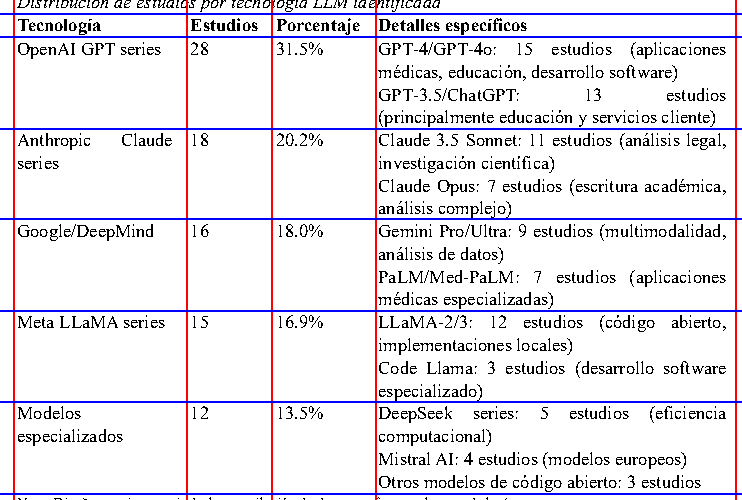

In [ ]:
# Verificación visual de los cortes - Tabla 1
pdf.pages[4].crop((75, 345, 520, 645)).to_image(resolution=120) \
    .draw_vlines([83, 187, 238, 300, 516], stroke="red", stroke_width=2) \
    .draw_hlines([353, 367, 422, 476, 531, 586, 641], stroke="blue", stroke_width=2)

In [ ]:
pagina = pdf.pages[6]
cortes = [83, 147, 197, 257, 311, 382, 433, 516]   # x donde empieza cada columna + borde derecho

filas = pagina.extract_table({
    "vertical_strategy": "explicit",
    "explicit_vertical_lines": cortes,
    "horizontal_strategy": "lines",
})

df2 = pd.DataFrame(filas[1:], columns=filas[0])
df2 = df2.replace("\n", " ", regex=True)
df2.columns = df2.columns.str.replace("\n", " ")
df2

,Modelo,MMLU (%),SWE- bench Verified (%),MATH- 500 (%),HumanEval (%),MedQA (%),Capacidades Especiales
0,OpenAI o3,90.2,-,-,-,-,Razonamiento avanzado
1,GPT-4.1,88.7,54.6,52.9,85.0,-,Contexto 1M tokens
2,GPT-4,86.4,-,52.9,67.0,-,Multimodal integrado
3,Gemini 2.5 Pro,85.4,63.8,-,99.0,-,Thinking model nativo
4,Claude 3.7 Sonnet,84.2,70.3,71.1,92.0,-,Razonamiento híbrido
5,Claude 3.5 Sonnet,-,-,71.1,-,-,Alucinación reducida
6,DeepSeek- R1,-,-,97.3,-,-,Eficiencia extrema
7,LLaMA- 3.3 70B,-,31.2,-,67.8,-,Código abierto
8,Med-PaLM 2,-,-,-,-,87.0,Especialización médica
9,GPT-3,43.9,-,14.5,29.0,-,Referencia histórica


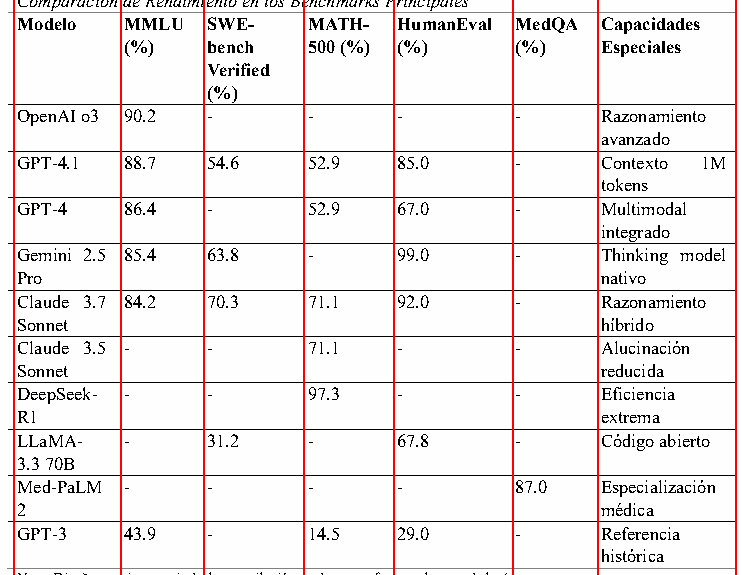

In [ ]:
# Verificación visual de los cortes - Tabla 2
pdf.pages[6].crop((75, 110, 520, 455)).to_image(resolution=120) \
    .draw_vlines([83, 147, 197, 257, 311, 382, 433, 516], stroke="red", stroke_width=2)

In [ ]:
pagina = pdf.pages[7]   # página 8 del PDF

columnas = [83, 155, 206, 268, 354, 442, 516]  # Sector | Estudios | Porcentaje | Tecnologías | Aplicaciones | Resultados | borde

tabla = pagina.extract_table({
    "vertical_strategy": "explicit",
    "explicit_vertical_lines": columnas,
    "horizontal_strategy": "lines",            # las filas salen de las rayitas
})

df4 = pd.DataFrame(tabla[1:], columns=tabla[0]).replace("\n", " ", regex=True)
df4.columns = df4.columns.str.replace("\n", " ")
df4

,Sector,Estudios,Porcentaje,Tecnologías predominantes,Aplicaciones principales,Resultados promedio
0,Salud,26,29.2%,"Med-PaLM 2, GPT-4, Claude 3.5","Diagnóstico asistido, documentación clínica, e...",83-87% precisión en benchmarks médicos
1,Educación,23,25.8%,"GPT-4, ChatGPT, Claude","Tutoría personalizada, generación de contenido...",25-40% mejora en engagement estudiantil
2,Desarrollo de Software,21,23.6%,"GitHub Copilot, Code Llama, GPT-4","Generación de código, debugging, documentación",35% incremento en productividad
3,Investigación Científica,12,13.5%,"GPT-4, Claude Opus, modelos especializados","Revisiones sistemáticas, análisis de datos, hi...",58% reducción en tiempo de revisión
4,Otros sectores,7,7.9%,Diversos,"Finanzas, legal, marketing, manufactura",Variable según sector


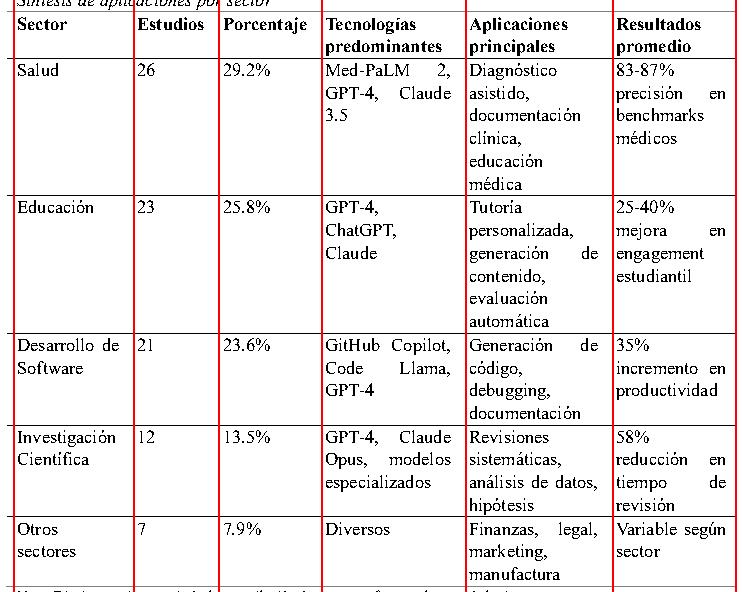

In [ ]:
# Verificación visual de los cortes - Tabla 4
pdf.pages[7].crop((75, 105, 520, 460)).to_image(resolution=120) \
    .draw_vlines([83, 155, 206, 268, 354, 442, 516], stroke="red", stroke_width=2)

## ¿Cómo se extraen las tablas del PDF?

Para armar una tabla, `pdfplumber` busca las líneas que forman la grilla: las verticales separan las columnas y las horizontales separan las filas.

El problema es que las tablas de este paper no tienen líneas verticales, solo algunas rayitas horizontales. Por eso `extract_tables()` con la configuración por defecto no detecta ninguna tabla y devuelve una lista vacía `[]`.

### Solución: dibujar las líneas a mano

Le indicamos a la librería en qué coordenadas van las líneas que faltan:

- **Eje x → columnas:** marcamos la posición donde empieza cada columna (justo antes de cada encabezado) y el borde derecho de la tabla.
- **Eje y → filas:** si la tabla tiene rayitas entre filas (Tablas 2 y 4), la librería las detecta sola con `"lines"`. Si no las tiene (Tabla 1), marcamos también la altura donde empieza cada fila.




#6. Analisis de Frecuencias

In [ ]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
N_PAGINA = 3

texto = doc[N_PAGINA - 1].get_text()
texto = re.sub(r"-\n(\w)", r"\1", texto) #Une las palabras cortadas con guion
texto = texto.lower()

print(texto[:100])

 
vol. 12/ núm. 3 2025 pág. 3125 
introducción 
la aparición de chatgpt en el mes de noviembre del 2


In [ ]:
#Tokenizar
tokens = word_tokenize(texto, language="spanish") #Separa las palabras y signos
print("Cantidad de tokens: ", len(tokens))

Cantidad de tokens:  410


In [ ]:
stop_words = set(stopwords.words("spanish"))

puntuacion = set(string.punctuation) | set ("¿¡«»“”‘’…–—") #se le agregan los signos utilizados en español

limpios = [t for t in tokens
           if t not in stop_words
           and t not in puntuacion
           and t.isalpha() #Solo palabras, descarta los numeros
           and len(t) > 1]

print(f"Tokens limpios: {len(limpios)}, antes del proceso de limpieza: {len(tokens)}")

Tokens limpios: 221, antes del proceso de limpieza: 410


In [ ]:
#Frecuencia
frecuencias = Counter(limpios)
top15 = frecuencias.most_common(15)
print(top15)

palabras, cantidades = zip(*top15)

[('global', 4), ('análisis', 4), ('modelos', 3), ('ia', 3), ('billones', 3), ('modelo', 3), ('transformer', 3), ('años', 2), ('adopción', 2), ('generativas', 2), ('innovación', 2), ('tecnológica', 2), ('vaswani', 2), ('et', 2), ('impacto', 2)]


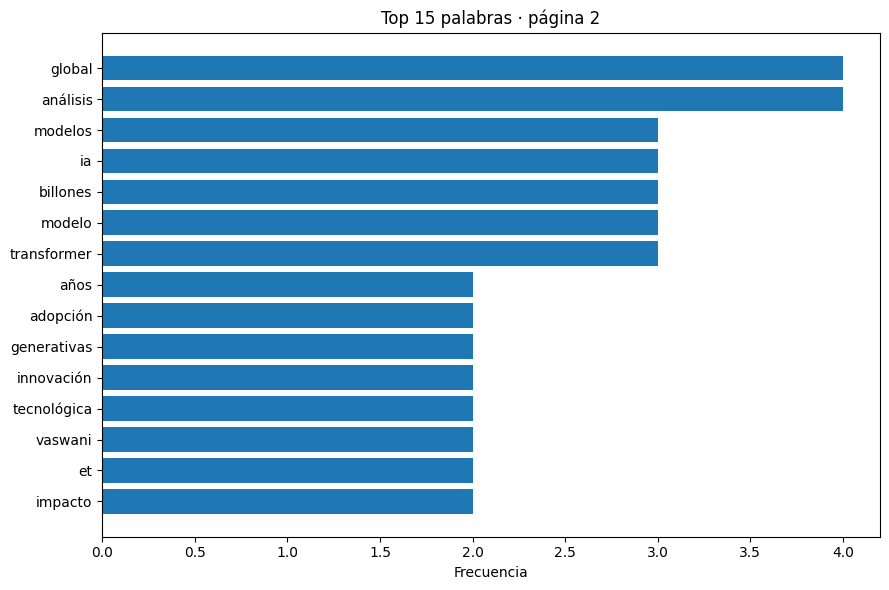

In [ ]:
plt.figure(figsize=(9, 6))
plt.barh(palabras, cantidades)
plt.gca().invert_yaxis()

plt.title(f"Top 15 palabras · página {N_PAGINA - 1}")
plt.xlabel("Frecuencia")
plt.tight_layout()
plt.show()